# Section 2 Task 3 — Exploring Where SNNs May Have Advantages

## Part A · 数据集调研

1. **名称、来源和任务。** Spiking Heidelberg Digits（SHD）是 Zenke Lab 发布的公开语音脉冲数据集。任务是识别英语和德语的数字 0–9，共 20 类。[官方数据主页](https://zenkelab.org/resources/spiking-heidelberg-datasets-shd/)
2. **格式、规模和主要特征。** 12 位说话者共提供 10,420 条样本，其中官方训练集 8,156 条，测试集 2,264 条。人工耳蜗模型把每段语音转换为 700 个通道的事件。HDF5 文件保存各脉冲的时间（秒）、通道编号，以及样本的类别和说话者编号。[数据集论文](https://doi.org/10.1109/TNNLS.2020.3044364)
3. **时间信息和脉冲转换。** 每条样本已包含脉冲时间戳，可以直接按时间窗统计已有事件，无需再将语音编码为脉冲。
4. **为什么适合 SNN。** 不同发音会产生随时间变化的通道活动。SNN 可以用神经元状态累积先后到达的脉冲，利用活动出现的时刻和通道来识别发音。输入以事件形式到达，也适合支持事件驱动的硬件。

## Part B · 基础实验

### 1. SHD 脉冲可视化

从官方训练集中选取同一位说话者的英语 `seven` 和德语 `sieben`。图中一个点代表一个脉冲，横轴以每条样本的首个事件为零点，纵轴是原始耳蜗通道编号。

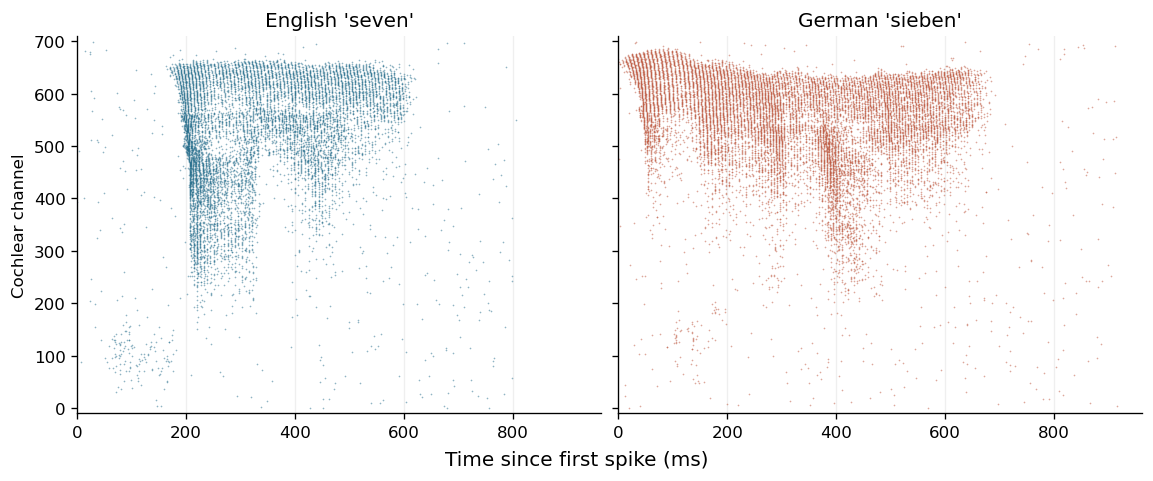

In [1]:
import json
import os
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np

directory = Path.cwd()
repo = next(
    path
    for path in (directory, *directory.parents)
    if (path / "spike_encoding" / "prepare_shd.py").is_file()
)
out = Path(
    os.environ.get("SHD_TASK3_OUTPUT", repo.parent / "outputs" / "Section2_Task3_SHD")
).resolve()
data = out / "data"

fig, axes = plt.subplots(
    1, 2, figsize=(9.5, 3.9), sharex=True, sharey=True, layout="constrained"
)
with h5py.File(data / "shd_train.h5", "r") as train:
    labels = train["labels"][:]
    speakers = train["extra/speaker"][:]
    class_names = [key.decode("utf-8") for key in train["extra/keys"][:]]
    examples = [(7, "English", "#176485"), (17, "German", "#b84a2f")]
    for ax, (label, language, color) in zip(axes, examples, strict=True):
        index = int(np.flatnonzero((labels == label) & (speakers == 1))[0])
        times_s = train["spikes/times"][index]
        times_ms = (times_s - times_s[0]) * 1000
        units = train["spikes/units"][index]
        ax.scatter(times_ms, units, s=1, alpha=0.48, color=color, linewidths=0)
        ax.set_title(f"{language} '{class_names[label]}'")
        ax.set_ylim(-10, 710)
        ax.grid(axis="x", alpha=0.2)
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)

axes[0].set_xlim(left=0)
axes[0].set_ylabel("Cochlear channel")
fig.supxlabel("Time since first spike (ms)")
fig.savefig(out / "shd_event_rasters.png", dpi=180, bbox_inches="tight")
plt.show()

英语样本较密集的活动出现在约 200 ms，德语样本在更早的时间就出现密集发放。两条样本的活跃通道都随时间变化，说明脉冲图保留了发音过程的信息。

### 2. 使用 SpikCommander 分类

直接加载 SpikCommander 1L-8-128 的作者权重（seed 312）。基准设置以首个事件为起点，每 10 ms 统计脉冲，将相邻 5 个耳蜗通道合并成 1 个，共 140 个输入通道。用 CPU 评估官方的 2,264 条测试样本，并按作者代码把各时间步的类别概率求和后取 Top-1。评估脚本适配了作者代码中的两个前向方法及旧权重键名，从原始文件加载权重。[论文](https://ojs.aaai.org/index.php/AAAI/article/view/37194) · [作者权重](https://github.com/JackieWang9811/SCommander/tree/a51266caba285d52cc022012dc7fb979a426f7eb/checkpoints/SHD)

从仓库根目录运行以下命令。评估脚本使用与仓库 CPU 配置相同的 PyTorch 和 torchvision，并需要 NumPy、Matplotlib、h5py、SciPy、Seaborn 和 tqdm。

```bash
python spike_encoding/prepare_shd.py
python spike_encoding/evaluate_spikcommander.py --device cpu
```

评估脚本下载并核验固定版本的作者源码与权重，在仓库同级的 `outputs/Section2_Task3_SHD` 写入实测结果。若给两个脚本设置了相同的 `--out`，运行 Notebook 时将环境变量 `SHD_TASK3_OUTPUT` 指向该目录。

### 3. 实验结果与时间窗口对性能的影响

时间窗口指输入的分箱宽度。以每条样本的首个事件为起点，将完整脉冲序列分别放入 5、10 和 20 ms 的非重叠窗口进行计数。三组使用同一份按 10 ms 配置训练的作者权重、相同的 140 个输入通道和相同的组批、读出设置，各在官方 2,264 条测试样本上推理一次。

In [2]:
from IPython.display import Markdown, display

result = json.loads((out / "spikcommander.json").read_text(encoding="utf-8"))
windows = result.get("window_results")
if windows is None:
    raise ValueError(
        "Run spike_encoding/evaluate_spikcommander.py to generate the window comparison."
    )

with h5py.File(data / "shd_test.h5", "r") as test:
    samples = len(test["labels"])
    assert all(row["samples"] == samples == 2264 for row in windows)

rows = ["| 分箱宽度 | 正确数 / 总数 | Top-1 准确率 |", "|---:|---:|---:|"]
for row in windows:
    accuracy = row["correct"] / row["samples"]
    rows.append(
        f"| {row['input_bin_ms']} ms | {row['correct']:,} / {row['samples']:,} | {accuracy:.2%} |"
    )
display(Markdown("\n".join(rows)))

| 分箱宽度 | 正确数 / 总数 | Top-1 准确率 |
|---:|---:|---:|
| 5 ms | 642 / 2,264 | 28.36% |
| 10 ms | 2,166 / 2,264 | 95.67% |
| 20 ms | 1,024 / 2,264 | 45.23% |

本次 CPU 推理中，**10 ms** 的准确率最高。5 ms 和 20 ms 相比 10 ms 分别下降 **67.31** 和 **50.44 个百分点**。较窄的窗口把事件分到更多时间步，较宽的窗口把更多事件合并到同一步，两者都会改变模型每一步接收的脉冲计数。这组结果表明，按 10 ms 训练的这份权重对推理时的分箱宽度敏感。